
DS-1: Python & Pandas EDA

Exploratory Data Analysis of Disney+ Movies and TV Shows

1.Introduction

Disney+ is a popular streaming platform that provides a wide variety of movies and TV shows. It contains content from different genres, countries, and release years.

In this project, I am performing Exploratory Data Analysis (EDA) on the Disney+ Movies and TV Shows dataset using Python. The main aim is to understand the dataset, identify patterns, and find useful information through data analysis and visualizations.

2.Objectives

- To understand the structure of the dataset.
- To identify missing values and duplicate records.
- To calculate basic statistical measures for numerical data.
- To analyze categorical data such as content type, country, and genre.
- To create different visualizations to understand the data better.
- To find interesting insights from the dataset.

3.Dataset Description

The dataset contains information about movies and TV shows available on Disney+. It includes details such as title, director, cast, country, release year, rating, duration, genre, and description.

The dataset is obtained from Kaggle.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting the visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Upload the dataset
from google.colab import files

uploaded = files.upload()


Saving disney_plus_titles.csv to disney_plus_titles.csv


In [2]:
# Loading the dataset into a DataFrame

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")


Dataset loaded successfully!



4.Structural Overview

In this section, I am examining the basic structure of the dataset. This includes the number of rows and columns, column names, data types, memory usage, and a preview of the first and last few records.


In [3]:
# Checking the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 1450
Number of columns: 12


In [4]:
# Displaying column names

print("Column Names:")
print(df.columns.tolist())


Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [5]:
# Checking the data types of each column

print("Data Types:")
print(df.dtypes)


Data Types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object


In [6]:
# Getting detailed information about the dataset

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1450 entries, 0 to 1449
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       1450 non-null   object
 1   type          1450 non-null   object
 2   title         1450 non-null   object
 3   director      977 non-null    object
 4   cast          1260 non-null   object
 5   country       1231 non-null   object
 6   date_added    1447 non-null   object
 7   release_year  1450 non-null   int64 
 8   rating        1447 non-null   object
 9   duration      1450 non-null   object
 10  listed_in     1450 non-null   object
 11  description   1450 non-null   object
dtypes: int64(1), object(11)
memory usage: 136.1+ KB


In [7]:
# Calculating memory usage

memory_usage = df.memory_usage(deep=True).sum()

print("Memory Usage:", round(memory_usage / (1024 ** 2), 2), "MB")


Memory Usage: 1.09 MB


In [8]:
# Displaying the first five rows

df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Duck the Halls: A Mickey Mouse Christmas Special,"Alonso Ramirez Ramos, Dave Wasson","Chris Diamantopoulos, Tony Anselmo, Tress MacN...",NaN,"November 26, 2021",2016,TV-G,23 min,"Animation, Family",Join Mickey and the gang as they duck the halls!
1,s2,Movie,Ernest Saves Christmas,John Cherry,"Jim Varney, Noelle Parker, Douglas Seale",NaN,"November 26, 2021",1988,PG,91 min,Comedy,Santa Claus passes his magic bag to a new St. ...
2,s3,Movie,Ice Age: A Mammoth Christmas,Karen Disher,"Raymond Albert Romano, John Leguizamo, Denis L...",United States,"November 26, 2021",2011,TV-G,23 min,"Animation, Comedy, Family",Sid the Sloth is on Santa's naughty list.
3,s4,Movie,The Queen Family Singalong,Hamish Hamilton,"Darren Criss, Adam Lambert, Derek Hough, Alexa...",NaN,"November 26, 2021",2021,TV-PG,41 min,Musical,"This is real life, not just fantasy!"
4,s5,TV Show,The Beatles: Get Back,NaN,"John Lennon, Paul McCartney, George Harrison, ...",NaN,"November 25, 2021",2021,NaN,1 Season,"Docuseries, Historical, Music",A three-part documentary from Peter Jackson ca...


In [9]:
# Displaying the last five rows

df.tail()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
1445,s1446,Movie,X-Men Origins: Wolverine,Gavin Hood,"Hugh Jackman, Liev Schreiber, Danny Huston, wi...","United States, United Kingdom","June 4, 2021",2009,PG-13,108 min,"Action-Adventure, Family, Science Fiction",Wolverine unites with legendary X-Men to fight...
1446,s1447,Movie,Night at the Museum: Battle of the Smithsonian,Shawn Levy,"Ben Stiller, Amy Adams, Owen Wilson, Hank Azar...","United States, Canada","April 2, 2021",2009,PG,106 min,"Action-Adventure, Comedy, Family",Larry Daley returns to rescue some old friends...
1447,s1448,Movie,Eddie the Eagle,Dexter Fletcher,"Tom Costello, Jo Hartley, Keith Allen, Dickon ...","United Kingdom, Germany, United States","December 18, 2020",2016,PG-13,107 min,"Biographical, Comedy, Drama","True story of Eddie Edwards, a British ski-jum..."
1448,s1449,Movie,Bend It Like Beckham,Gurinder Chadha,"Parminder Nagra, Keira Knightley, Jonathan Rhy...","United Kingdom, Germany, United States","September 18, 2020",2003,PG-13,112 min,"Buddy, Comedy, Coming of Age",Despite the wishes of their traditional famili...
1449,s1450,Movie,Captain Sparky vs. The Flying Saucers,Mark Waring,Charlie Tahan,United States,"April 1, 2020",2012,TV-G,2 min,"Action-Adventure, Animals & Nature, Animation",View one of Sparky's favorite home movies.


In [27]:
# Checking for duplicate rows
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0



5.Missing Value Analysis

In this section, I am checking the dataset for missing values. This helps to identify incomplete data and understand the quality of the dataset before performing further analysis.


In [10]:
# Checking the number of missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)


Missing Values in Each Column:
show_id           0
type              0
title             0
director        473
cast            190
country         219
date_added        3
release_year      0
rating            3
duration          0
listed_in         0
description       0
dtype: int64


In [11]:
# Calculating the percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))


Missing Value Percentage:
show_id          0.00
type             0.00
title            0.00
director        32.62
cast            13.10
country         15.10
date_added       0.21
release_year     0.00
rating           0.21
duration         0.00
listed_in        0.00
description      0.00
dtype: float64


In [12]:
# Creating a summary table of missing values

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

display(missing_summary.round(2))


,Missing Values,Percentage (%)
director,473,32.62
cast,190,13.10
country,219,15.10
date_added,3,0.21
rating,3,0.21


Interpretation

The director column has the highest number of missing values, with 473 entries (32.62%). The country and cast columns also contain a considerable number of missing values. In comparison, the date_added and rating columns have only 3 missing values each (0.21%).

This shows that the dataset has incomplete information mainly about directors, cast members, and countries.


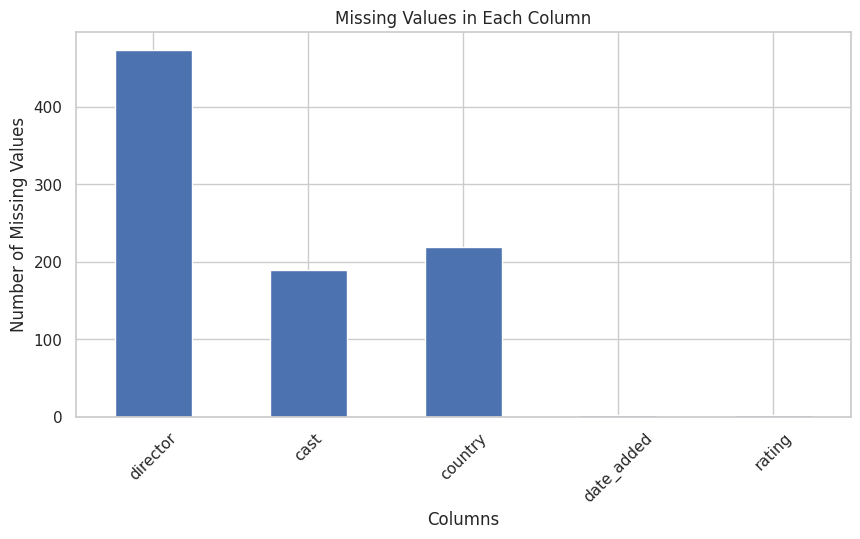

In [13]:
# Visualizing missing values using a bar chart

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if len(missing_counts) > 0:
    missing_counts.plot(kind='bar', figsize=(10, 5))

    plt.title('Missing Values in Each Column')
    plt.xlabel('Columns')
    plt.ylabel('Number of Missing Values')
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No missing values found in the dataset.")


 Interpretation

The bar chart shows that the director column has the highest number of missing values, followed by the country and cast columns. The date_added and rating columns have very few missing values in comparison.

This indicates that information about directors, countries, and cast members is incomplete for some titles in the dataset.


6.Numerical Summary Statistics

In this section, I am calculating summary statistics for the numerical columns in the dataset. These measures help me understand the distribution and variation of the numerical data.


In [14]:
# Calculating summary statistics for numerical columns

df.describe()


,release_year
count,1450.000000
mean,2003.091724
std,21.860162
min,1928.000000
25%,1999.000000
50%,2011.000000
75%,2018.000000
max,2021.000000


Interpretation

The release_year column contains 1,450 records, with an average release year of approximately 2003. The earliest title was released in 1928, while the latest was released in 2021.

The median release year is 2011, indicating that half of the titles were released before 2011 and half after. The data shows that the Disney+ content includes both older classics and more recent releases.


In [15]:
# Calculating the median of numerical columns

df.median(numeric_only=True)


,0
release_year,2011.0


In [16]:
# Calculating the Standard Deviation of numerical columns
df.std(numeric_only=True)

,0
release_year,21.860162


7.Categorical Data Analysis

In this section, I am analyzing categorical columns to understand the distribution of different types of content in the Disney+ dataset.

In [17]:
# Value counts for content type
df['type'].value_counts()

,count
type,
Movie,1052
TV Show,398


In [18]:
# Value counts for content ratings
df['rating'].value_counts()

,count
rating,
TV-G,318
TV-PG,301
G,253
PG,236
TV-Y7,131
TV-14,79
PG-13,66
TV-Y,50
TV-Y7-FV,13


In [19]:
# Value counts for countries
df['country'].value_counts().head(10)

,count
country,
United States,1005
"United States, Canada",30
United Kingdom,23
"United States, United Kingdom",22
"Canada, United States",17
"United Kingdom, United States",14
"United States, Australia",8
Canada,6
"United States, United Kingdom, Australia",4


In [20]:
# Value counts for genres
df['listed_in'].value_counts().head(10)

,count
listed_in,
"Animation, Comedy, Family",124
"Action-Adventure, Animation, Comedy",77
"Action-Adventure, Animation, Kids",45
"Animals & Nature, Documentary, Family",40
"Action-Adventure, Animation, Family",40
"Animals & Nature, Docuseries, Family",39
"Animals & Nature, Documentary",35
"Animation, Family, Fantasy",31
"Action-Adventure, Comedy, Family",28


8.Data Visualization

8.1Distribution of Content Type

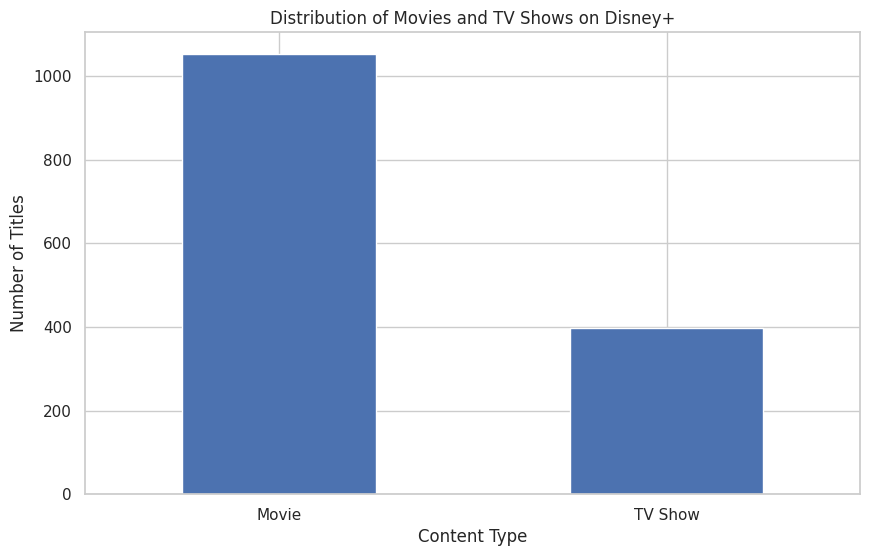

In [21]:
# Bar chart showing the distribution of content types
df['type'].value_counts().plot(kind='bar')

plt.title('Distribution of Movies and TV Shows on Disney+')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()

Interpretation: The dataset contains significantly more Movies than TV Shows. Movies account for the majority of the content available in this dataset.

8.2 Distribution of Release Years

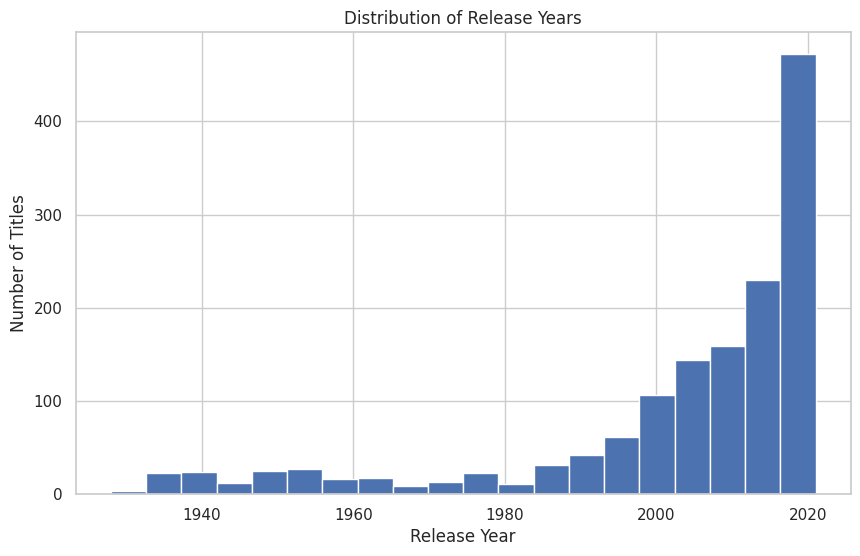

In [22]:
# Histogram showing the distribution of release years
plt.hist(df['release_year'], bins=20)

plt.title('Distribution of Release Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

Interpretation:The dataset contains more titles released in recent years compared to older decades. The highest concentration of titles is observed in the period around 2015–2021.

8.3 Distribution of Content Ratings

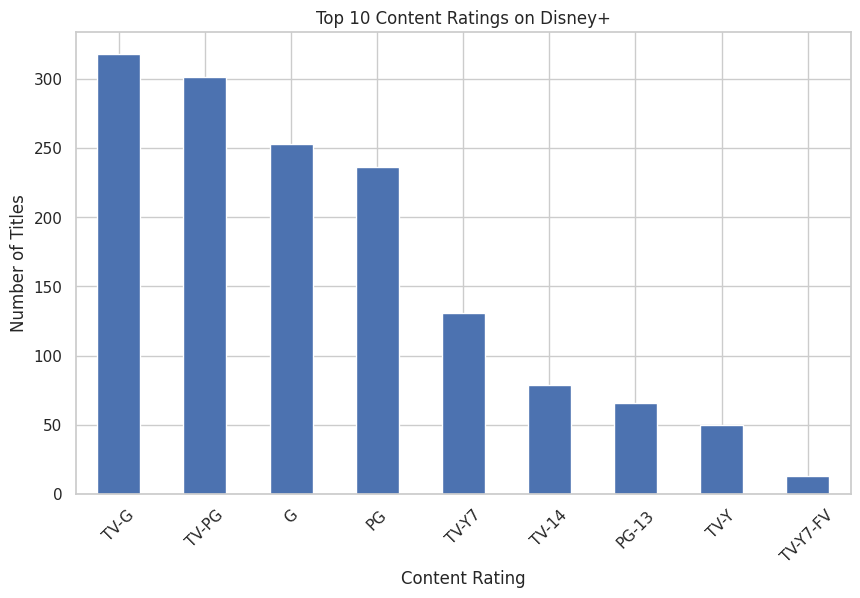

In [23]:
# Bar chart showing the distribution of content ratings
df['rating'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Content Ratings on Disney+')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.show()

Interpretation: TV-G has the highest number of titles, followed by TV-PG, G, and PG. This indicates that a large portion of the Disney+ content is suitable for general audiences or younger viewers.

8.4 Proportion of Movies and TV Shows

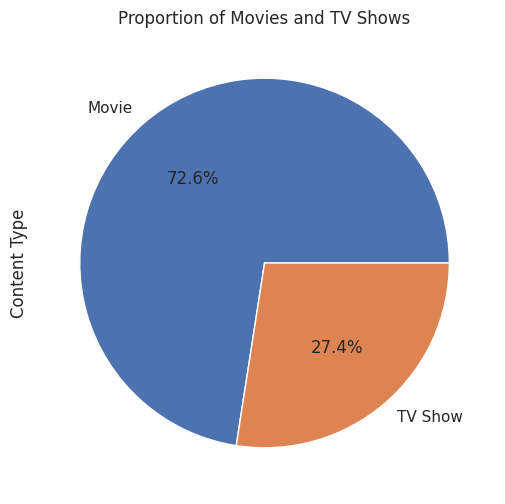

In [24]:
# Pie chart showing the proportion of Movies and TV Shows
df['type'].value_counts().plot(kind='pie', autopct='%1.1f%%')

plt.title('Proportion of Movies and TV Shows')
plt.ylabel('Content Type')
plt.show()

Interpretation: Movies make up 72.6% of the dataset, while TV Shows account for 27.4%. This confirms that the Disney+ dataset is dominated by Movies.

8.5 Top 10 Genres on Disney+

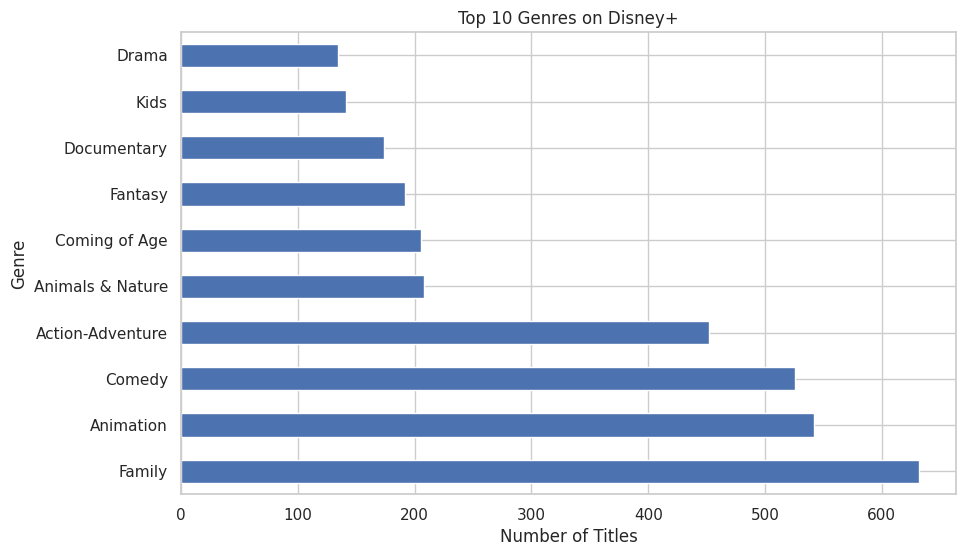

In [25]:
# Finding the top 10 genres
genres = df['listed_in'].str.split(', ').explode()
top_genres = genres.value_counts().head(10)

# Horizontal bar chart
top_genres.plot(kind='barh')

plt.title('Top 10 Genres on Disney+')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

Interpretation: Family is the most common genre in the Disney+ dataset, followed by Animation and Comedy. This suggests that family-oriented and animated content form a major part of the platform's library.

9.Key Findings

1.Movies account for 72.6% of the dataset, while TV Shows make up 27.4%.

2.The dataset contains more titles released in recent years, especially around 2015–2021.

3.TV-G is the most common content rating, followed by TV-PG.

4.The United States is the most frequently listed country in the dataset.

5.Family is the most common genre, followed by Animation and Comedy.